# Deepfake Detection with CLIP ViT-L/14 + LoRA

**Architecture**: CLIP ViT-L/14 visual encoder (frozen) → PEFT LoRA adapters → Binary classification head  
**Dataset**: OpenFake subset — real images vs. synthetic images from Stable Diffusion and Midjourney families  
**Evaluation**: Accuracy, Precision, Recall, F1, ROC AUC reported for **train / val / test** splits, overall and per-family  

---

## 1. Setup & Installation

In [1]:
# Install required libraries (output suppressed for cleaner notebook)
%%capture
!pip install -q --upgrade torchao
!pip install -q transformers peft accelerate datasets pillow scikit-learn matplotlib seaborn tqdm

## 2. Configuration

Every hyperparameter and path is defined here in one place.  
Toggle `DEBUG = True` to run the entire pipeline on a tiny sample (~100 images) with fewer epochs — useful for verifying that everything works before committing to a full training run.

In [2]:
import os
from pathlib import Path

# ============================================================
# DEBUG MODE
# True  → ~100 samples per split, 2 epochs, fast validation
# False → full dataset, 10 epochs, production run
# ============================================================
DEBUG = False

# ── Paths on Google Drive ──
PROJECT_DIR  = Path("/content/drive/MyDrive/Image Processing Project/CLIP Based")
ZIP_PATH     = PROJECT_DIR / "preprocessed_256_outputs" / "archives" / "openfake_split_256.zip"  # zipped dataset
METADATA_CSV = PROJECT_DIR / "metadata.csv"   # original metadata: columns = image_path, prompt, label, model
OUTPUT_DIR   = PROJECT_DIR / "outputs"         # all saved artifacts (models, plots, JSON) go here

# ── Local extraction path ──
# Extracting to Colab's local disk (/content/) is much faster for I/O than
# reading images directly from Google Drive during training.
LOCAL_DATA_DIR = Path("/content/openfake_data")

# ── Hyperparameters ──
CONFIG = {
    # ----- Model backbone -----
    "model_name": "openai/clip-vit-large-patch14",  # CLIP ViT-L/14: 768-dim projection
    "image_size": 224,                               # CLIP's expected input resolution

    # ----- LoRA (Low-Rank Adaptation) -----
    # Only the Q and V projection matrices in each attention layer get LoRA adapters.
    # This keeps ~99% of the backbone frozen while allowing task-specific fine-tuning.
    "lora_r": 16,           # rank of the low-rank matrices (higher = more capacity)
    "lora_alpha": 32,       # scaling factor (alpha/r controls effective learning rate of adapters)
    "lora_dropout": 0.1,    # dropout applied inside LoRA layers for regularisation

    # ----- Classification head -----
    # A small MLP on top of CLIP's projected embeddings: Linear → GELU → Linear → 2 classes.
    # GELU is used for consistency with CLIP's internal transformer activation function.
    "head_hidden_dim": 256,  # hidden layer size between the two linear layers
    "head_dropout": 0.1,     # dropout before each linear layer

    # ----- Training -----
    "batch_size": 32 if not DEBUG else 8,
    "num_epochs": 5 if not DEBUG else 2,
    "learning_rate": 2e-4,    # AdamW learning rate
    "weight_decay": 0.01,     # L2 regularisation strength
    "max_grad_norm": 1.0,     # gradient clipping to prevent exploding gradients

    # ----- LR Scheduler: ReduceLROnPlateau -----
    # Reduces LR by `lr_factor` when val ROC AUC hasn't improved for `lr_patience` epochs.
    # Pairs naturally with early stopping — both watch the same metric.
    "lr_patience": 2,
    "lr_factor": 0.5,

    # ----- Early Stopping -----
    # Stops training when val ROC AUC hasn't improved for `early_stop_patience` epochs.
    # The best checkpoint (by val ROC AUC) is saved and used for final test evaluation.
    "early_stop_patience": 1 if not DEBUG else 1,

    # ----- Data -----
    "max_samples_per_split": None if not DEBUG else 10,
    "seed": 42,
}

# ── Generator Family Mapping ──
# Maps each individual generator model name (from the 'model' column in metadata)
# to one of 3 families:
#   1. Real             — authentic photographs
#   2. Stable Diffusion — all SD versions (1.5, 2.1, 3.5) and SDXL variants/finetunes
#   3. Midjourney       — Midjourney v6 and v7
MODEL_TO_FAMILY = {
    # Real images
    "real": "Real",
    # Stable Diffusion 1.x and its finetunes
    "sd-1.5": "Stable Diffusion",
    "sd-1.5-dreamshaper": "Stable Diffusion",
    "sd-1.5-epicdream": "Stable Diffusion",
    # Stable Diffusion 2.x
    "sd-2.1": "Stable Diffusion",
    # Stable Diffusion 3.x
    "sd-3.5": "Stable Diffusion",
    # SDXL base and community finetunes/LoRAs
    "sdxl": "Stable Diffusion",
    "sdxl-epic-realism": "Stable Diffusion",
    "sdxl-touchofrealism": "Stable Diffusion",
    "sdxl-realvis-v5": "Stable Diffusion",
    "sdxl-juggernaut": "Stable Diffusion",
    # Midjourney
    "midjourney-6": "Midjourney",
    "midjourney-7": "Midjourney",
}

print(f"DEBUG mode: {DEBUG}")
print(f"Zip path:   {ZIP_PATH}")
print(f"Metadata:   {METADATA_CSV}")
print(f"Output dir: {OUTPUT_DIR}")

DEBUG mode: False
Zip path:   /content/drive/MyDrive/Image Processing Project/CLIP Based/preprocessed_256_outputs/archives/openfake_split_256.zip
Metadata:   /content/drive/MyDrive/Image Processing Project/CLIP Based/metadata.csv
Output dir: /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs


## 3. Mount Drive & Extract Dataset

In [3]:
from google.colab import drive
import shutil

# Mount Google Drive (unmount first if already mounted from a previous run)
if os.path.ismount('/content/drive'):
    drive.flush_and_unmount()
drive.mount('/content/drive')

# Verify that the zip and metadata exist on Drive
assert ZIP_PATH.exists(), f"Dataset zip not found at {ZIP_PATH}"
assert METADATA_CSV.exists(), f"Metadata CSV not found at {METADATA_CSV}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("✓ Drive mounted, zip and metadata found")

Mounted at /content/drive
✓ Drive mounted, zip and metadata found


In [4]:
import zipfile

# ── Extract the dataset to Colab's local disk ──
# Reading thousands of small image files directly from Google Drive is very slow.
# Extracting to /content/ (local SSD) gives much better I/O throughput during training.
# This cell is safe to re-run — it skips extraction if the directory already exists.

if LOCAL_DATA_DIR.exists() and any(LOCAL_DATA_DIR.iterdir()):
    print(f"✓ Data already extracted at {LOCAL_DATA_DIR}, skipping")
else:
    LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_file = str(ZIP_PATH)

    # The path might be a .zip file or a directory name without extension
    # Try both: with .zip extension and without
    if not zip_file.endswith('.zip'):
        zip_file_with_ext = zip_file + '.zip'
    else:
        zip_file_with_ext = zip_file

    # Find the actual zip file
    if os.path.isfile(zip_file_with_ext):
        actual_zip = zip_file_with_ext
    elif os.path.isfile(zip_file):
        actual_zip = zip_file
    else:
        raise FileNotFoundError(
            f"Could not find zip file. Tried:\n  {zip_file}\n  {zip_file_with_ext}\n"
            f"Contents of parent dir: {list(Path(zip_file).parent.glob('*'))}"
        )

    print(f"Extracting {actual_zip} → {LOCAL_DATA_DIR}")
    with zipfile.ZipFile(actual_zip, 'r') as zf:
        zf.extractall(LOCAL_DATA_DIR)
    print(f"✓ Extraction complete")

# ── Locate the split directories ──
# The zip might extract directly as train/val/test/ or inside a subfolder.
# Auto-detect by looking for the 'train' directory.
if (LOCAL_DATA_DIR / "train").exists():
    IMAGE_ROOT = LOCAL_DATA_DIR
else:
    # Check one level deeper (e.g., openfake_split_256/train/)
    subdirs = [d for d in LOCAL_DATA_DIR.iterdir() if d.is_dir()]
    IMAGE_ROOT = None
    for sd in subdirs:
        if (sd / "train").exists():
            IMAGE_ROOT = sd
            break
    if IMAGE_ROOT is None:
        raise FileNotFoundError(
            f"Could not find train/ directory inside {LOCAL_DATA_DIR}.\n"
            f"Contents: {list(LOCAL_DATA_DIR.rglob('*'))[:20]}"
        )

# Print what we found
print(f"\nImage root: {IMAGE_ROOT}")
for split in ["train", "val", "test"]:
    for cls in ["real", "fake"]:
        p = IMAGE_ROOT / split / cls
        n = len(list(p.glob("*"))) if p.exists() else 0
        print(f"  {split}/{cls}: {n:>6} images")

Extracting /content/drive/MyDrive/Image Processing Project/CLIP Based/preprocessed_256_outputs/archives/openfake_split_256.zip → /content/openfake_data
✓ Extraction complete

Image root: /content/openfake_data
  train/real:   2400 images
  train/fake:   4791 images
  val/real:    300 images
  val/fake:    598 images
  test/real:    300 images
  test/fake:    600 images


## 4. Imports & Reproducibility

In [5]:
import random
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from transformers import CLIPModel, CLIPProcessor
from peft import LoraConfig, get_peft_model

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ── Logging setup ──
class Log:
    def info(self, msg): print(f"[INFO] {msg}")
    def warning(self, msg): print(f"[WARN] {msg}")
log = Log()

# ── Seed everything for reproducibility ──
# Sets Python, NumPy, and PyTorch random seeds so results are deterministic
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CONFIG["seed"])

# ── Device selection ──
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log.info(f"Device: {DEVICE}")
if torch.cuda.is_available():
    log.info(f"GPU: {torch.cuda.get_device_name(0)}")

[INFO] Device: cuda
[INFO] GPU: Tesla T4


## 5. Dataset

The `DeepfakeDataset` class:
1. Walks the `split/real/` and `split/fake/` directories to find images.
2. Joins each filename with the metadata CSV to look up which generator model produced it.
3. Applies CLIP's preprocessor (resize to 224×224, normalise to CLIP's expected pixel distribution).
4. Returns pixel values, a binary label (0=real, 1=fake), and the generator model name (for per-family analysis).

In [6]:
class DeepfakeDataset(Dataset):
    """
    Binary classification dataset for deepfake detection.

    Each sample is a tuple of (pixel_values, label, model_name) where:
    - pixel_values: preprocessed image tensor ready for CLIP
    - label: 0 = real, 1 = fake
    - model_name: the generator that produced the image (e.g. 'sd-3.5', 'midjourney-6')
                  Used during evaluation for per-family breakdowns, not during training.
    """

    def __init__(self, image_root, split, processor, metadata_df, max_samples=None):
        """
        Args:
            image_root:   Path containing train/, val/, test/ subdirectories.
            split:        One of 'train', 'val', 'test'.
            processor:    CLIPProcessor instance for image preprocessing.
            metadata_df:  DataFrame with 'image_path' and 'model' columns.
            max_samples:  If set, randomly subsample to this many images (for DEBUG mode).
        """
        self.processor = processor
        self.samples = []  # list of (filepath, label, model_name)

        split_dir = Path(image_root) / split
        label_map = {"real": 0, "fake": 1}  # directory name → binary label

        # Build a lookup: filename → generator model name
        # The metadata's 'image_path' column has full paths like
        # '/content/openfake_subset/images/0.jpg' — we extract just the filename.
        fname_to_model = {}
        if metadata_df is not None:
            for _, row in metadata_df.iterrows():
                fname = Path(str(row["image_path"])).name  # e.g. '0.jpg'
                fname_to_model[fname] = row["model"]       # e.g. 'sd-3.5'

        # Walk each class directory (real/ and fake/) and collect image paths
        for cls_name, label in label_map.items():
            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                log.warning(f"Directory missing: {cls_dir}")
                continue

            for fp in sorted(cls_dir.glob("*")):
                # Only include common image formats
                if fp.suffix.lower() in (".jpg", ".jpeg", ".png", ".webp", ".bmp"):
                    # Look up the generator from metadata; default to 'real' for
                    # images not found in metadata (e.g. real images)
                    model_name = fname_to_model.get(fp.name, cls_name)
                    self.samples.append((str(fp), label, model_name))

        # In DEBUG mode, randomly subsample to keep things fast
        if max_samples and len(self.samples) > max_samples:
            random.shuffle(self.samples)
            self.samples = self.samples[:max_samples]

        # Log the split composition
        n_real = sum(1 for _, l, _ in self.samples if l == 0)
        n_fake = sum(1 for _, l, _ in self.samples if l == 1)
        log.info(f"  [{split:>5}] {len(self.samples):>6} images  (real={n_real}, fake={n_fake})")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, model_name = self.samples[idx]

        # Load and convert to RGB (handles grayscale or RGBA images)
        try:
            image = Image.open(path).convert("RGB")
        except Exception:
            # Fallback: return a black image if the file is corrupted
            image = Image.new("RGB", (CONFIG["image_size"], CONFIG["image_size"]))

        # CLIP preprocessor: resizes to 224x224, normalises pixel values
        inputs = self.processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].squeeze(0)  # remove batch dim

        return {
            "pixel_values": pixel_values,
            "label": torch.tensor(label, dtype=torch.long),
            "model_name": model_name,  # string — used only during evaluation
        }

In [7]:
# ── Load metadata ──
# Columns: image_path, prompt, label, model
metadata_df = pd.read_csv(METADATA_CSV)
log.info(f"Metadata loaded: {len(metadata_df)} rows, models: {metadata_df['model'].nunique()}")

# CLIP processor handles resizing (to 224x224) and normalisation
processor = CLIPProcessor.from_pretrained(CONFIG["model_name"])

# ── Build datasets ──
# IMAGE_ROOT was set in the extraction cell (Section 3)
log.info("Building datasets...")
train_ds = DeepfakeDataset(IMAGE_ROOT, "train", processor, metadata_df, CONFIG["max_samples_per_split"])
val_ds   = DeepfakeDataset(IMAGE_ROOT, "val",   processor, metadata_df, CONFIG["max_samples_per_split"])
test_ds  = DeepfakeDataset(IMAGE_ROOT, "test",  processor, metadata_df, CONFIG["max_samples_per_split"])

# DataLoaders: shuffle training data, keep val/test in order for reproducibility
train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0, pin_memory=True)

[INFO] Metadata loaded: 8989 rows, models: 13


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

[INFO] Building datasets...
[INFO]   [train]   7191 images  (real=2400, fake=4791)
[INFO]   [  val]    898 images  (real=300, fake=598)
[INFO]   [ test]    900 images  (real=300, fake=600)


## 6. Model Architecture

The model has three components:

1. **CLIP Vision Encoder** (frozen): Extracts visual features using a ViT-L/14 transformer. All weights are frozen — we don't want to destroy the pretrained representations.

2. **LoRA Adapters**: Injected into the Q (query) and V (value) projection matrices of each attention layer. These are small trainable matrices that adapt the frozen encoder to our task with very few parameters (~0.5% of total).

3. **Classification Head**: A small MLP that takes the 768-dim CLIP embedding and outputs 2 logits (real vs fake):
   - LayerNorm → Dropout → Linear(768→256) → GELU → Dropout → Linear(256→2)

In [8]:
class CLIPDeepfakeDetector(nn.Module):
    """
    Deepfake detector built on CLIP's visual encoder.

    Forward pass:
        pixel_values → VisionEncoder (frozen+LoRA) → pooled output
                     → visual_projection (frozen)  → 768-dim embedding
                     → classifier head              → 2 logits [real, fake]
    """

    def __init__(self, config, lora_config):
        super().__init__()

        # Load the full CLIP model, then extract only the vision components
        clip = CLIPModel.from_pretrained(config["model_name"])
        self.vision_model = clip.vision_model            # ViT-L/14 encoder
        self.visual_projection = clip.visual_projection  # projects to 768-dim shared space

        # Freeze all backbone parameters — we only want to train LoRA + head
        for p in self.vision_model.parameters():
            p.requires_grad = False
        for p in self.visual_projection.parameters():
            p.requires_grad = False

        # Inject LoRA adapters into the attention Q and V projection matrices.
        # This makes a small subset of the encoder trainable (~0.5% of params).
        self.vision_model = get_peft_model(self.vision_model, lora_config)

        # ── Classification head ──
        # All dimensions and dropout rates come from CONFIG (no hardcoded values).
        embed_dim  = clip.config.projection_dim   # 768 for ViT-L/14
        hidden_dim = config["head_hidden_dim"]     # 256 by default
        dropout    = config["head_dropout"]         # 0.1 by default

        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),              # stabilise CLIP embeddings
            nn.Dropout(dropout),                  # regularisation
            nn.Linear(embed_dim, hidden_dim),     # 768 → 256
            nn.GELU(),                            # matches CLIP's internal activation
            nn.Dropout(dropout),                  # regularisation
            nn.Linear(hidden_dim, 2),             # 256 → 2 (real vs fake logits)
        )

    def forward(self, pixel_values):
        # Step 1: Extract visual features (LoRA adapters are active here)
        vision_out = self.vision_model(pixel_values=pixel_values)
        pooled = vision_out.pooler_output                    # [batch, 1024]

        # Step 2: Project to CLIP's shared embedding space
        projected = self.visual_projection(pooled)           # [batch, 768]

        # Step 3: Classify as real (0) or fake (1)
        logits = self.classifier(projected)                  # [batch, 2]
        return logits

In [9]:
# ── Build the LoRA config ──
# target_modules: which layers get LoRA adapters
# q_proj / v_proj = query and value projections in each attention head
lora_config = LoraConfig(
    r=CONFIG["lora_r"],
    lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=CONFIG["lora_dropout"],
    target_modules=["q_proj", "v_proj"],
    bias="none",  # don't add trainable biases to LoRA layers
)

# ── Instantiate and move to GPU ──
model = CLIPDeepfakeDetector(CONFIG, lora_config).to(DEVICE)

# ── Parameter summary ──
# Shows how few parameters are actually trainable thanks to LoRA
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
log.info(f"Total params:     {total_params:>12,}")
log.info(f"Trainable params: {trainable_params:>12,} ({100*trainable_params/total_params:.2f}%)")
model.vision_model.print_trainable_parameters()

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[INFO] Total params:      305,737,986
[INFO] Trainable params:    1,771,778 (0.58%)
trainable params: 1,572,864 || all params: 304,752,640 || trainable%: 0.5161


## 7. Training Utilities

In [10]:
class EarlyStopping:
    """Stops training when the monitored metric (val ROC AUC) stops improving.

    Usage:
        es = EarlyStopping(patience=4)
        improved = es.step(val_auc)   # True if this is the best score so far
        if es.should_stop: break      # True when patience is exhausted
    """

    def __init__(self, patience, min_delta=1e-4):
        self.patience = patience       # how many epochs to wait after last improvement
        self.min_delta = min_delta     # minimum change to count as improvement
        self.best_score = -float("inf")
        self.counter = 0               # epochs since last improvement
        self.should_stop = False

    def step(self, score):
        """Returns True if score improved (new best), False otherwise."""
        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter = 0
            return True   # new best → save checkpoint
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False  # no improvement

In [11]:
def run_epoch(model, loader, criterion, optimizer=None, desc="Train"):
    """
    Run one full pass through a dataloader.

    Args:
        model:     The detector model.
        loader:    DataLoader for the split.
        criterion: Loss function (CrossEntropyLoss).
        optimizer: If provided → training mode (forward + backward + weight update).
                   If None    → eval mode (forward only, no gradients).
        desc:      Label for the progress bar.

    Returns:
        Dict with loss, accuracy, f1_macro, roc_auc for this epoch.
    """
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    # Use gradients only during training; disable for efficiency during eval
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        pbar = tqdm(loader, desc=desc, leave=False)
        for batch in pbar:
            pixel_values = batch["pixel_values"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            # Forward pass: raw logits [batch, 2]
            logits = model(pixel_values)
            loss = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad()           # clear old gradients
                loss.backward()                 # compute new gradients
                # Clip gradients to prevent exploding gradient problem
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
                optimizer.step()                # update weights

            # Accumulate predictions for metric computation
            total_loss += loss.item() * labels.size(0)
            probs = torch.softmax(logits, dim=1)[:, 1]  # P(fake) — probability of class 1
            preds = logits.argmax(dim=1)                 # predicted class (0 or 1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())
            pbar.set_postfix(loss=f"{loss.item():.4f}")

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    # ROC AUC needs both classes present; handle edge case
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = 0.0

    return {
        "loss": total_loss / len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "roc_auc": auc,
    }

## 8. Training Loop

**How the three sets are used:**
- **Train set**: Model learns from this data (forward + backward pass).
- **Val set**: Evaluated after each epoch. Drives model selection (save best checkpoint) and early stopping. The model never trains on this data.
- **Test set**: Touched **once** after training is complete, using the best checkpoint. Gives an unbiased performance estimate.

In [12]:
# ── Loss function: CrossEntropyLoss for binary classification (2 output logits) ──
criterion = nn.CrossEntropyLoss()

# ── Optimizer: AdamW with decoupled weight decay — standard for fine-tuning transformers ──
# Only trainable parameters (LoRA adapters + classifier head) are passed.
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

# ── LR Scheduler: ReduceLROnPlateau ──
# Watches val ROC AUC (mode='max'). If it doesn't improve for lr_patience epochs,
# the learning rate is multiplied by lr_factor (halved by default).
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=CONFIG["lr_factor"], patience=CONFIG["lr_patience"],
)

# ── Early Stopping ──
early_stopper = EarlyStopping(patience=CONFIG["early_stop_patience"])

In [13]:
log.info("=" * 60)
log.info("Starting training")
log.info("=" * 60)

# Store per-epoch metrics for plotting later
history = {"train": [], "val": []}
best_model_path = OUTPUT_DIR / "best_model.pt"

for epoch in range(1, CONFIG["num_epochs"] + 1):
    current_lr = optimizer.param_groups[0]['lr']
    log.info(f"\n--- Epoch {epoch}/{CONFIG['num_epochs']}  (lr={current_lr:.2e}) ---")

    # Training pass (optimizer provided → gradients + weight updates)
    train_m = run_epoch(model, train_loader, criterion, optimizer, desc=f"Train E{epoch}")

    # Validation pass (optimizer=None → no gradients, evaluation only)
    val_m = run_epoch(model, val_loader, criterion, optimizer=None, desc=f"Val E{epoch}")

    history["train"].append(train_m)
    history["val"].append(val_m)

    log.info(
        f"  Train — Loss: {train_m['loss']:.4f}  Acc: {train_m['accuracy']:.4f}  "
        f"F1: {train_m['f1_macro']:.4f}  ROC AUC: {train_m['roc_auc']:.4f}"
    )
    log.info(
        f"  Val   — Loss: {val_m['loss']:.4f}  Acc: {val_m['accuracy']:.4f}  "
        f"F1: {val_m['f1_macro']:.4f}  ROC AUC: {val_m['roc_auc']:.4f}"
    )

    # Step scheduler based on val ROC AUC
    scheduler.step(val_m["roc_auc"])

    # Check early stopping
    improved = early_stopper.step(val_m["roc_auc"])
    if improved:
        torch.save(model.state_dict(), best_model_path)
        log.info(f"  ✓ Best model saved (Val ROC AUC: {val_m['roc_auc']:.4f})")
    else:
        log.info(f"  ✗ No improvement ({early_stopper.counter}/{early_stopper.patience})")

    if early_stopper.should_stop:
        log.info(f"  ⏹ Early stopping triggered at epoch {epoch}")
        break

log.info(f"\nTraining complete. Best Val ROC AUC: {early_stopper.best_score:.4f}")

[INFO] ============================================================
[INFO] Starting training
[INFO] ============================================================
[INFO] 
--- Epoch 1/5  (lr=2.00e-04) ---


Train E1:   0%|          | 0/225 [00:00<?, ?it/s]

Val E1:   0%|          | 0/29 [00:00<?, ?it/s]

[INFO]   Train — Loss: 0.1965  Acc: 0.9123  F1: 0.8989  ROC AUC: 0.9732
[INFO]   Val   — Loss: 0.1103  Acc: 0.9566  F1: 0.9516  ROC AUC: 0.9932
[INFO]   ✓ Best model saved (Val ROC AUC: 0.9932)
[INFO] 
--- Epoch 2/5  (lr=2.00e-04) ---


Train E2:   0%|          | 0/225 [00:00<?, ?it/s]

Val E2:   0%|          | 0/29 [00:00<?, ?it/s]

[INFO]   Train — Loss: 0.0445  Acc: 0.9854  F1: 0.9836  ROC AUC: 0.9984
[INFO]   Val   — Loss: 0.1352  Acc: 0.9677  F1: 0.9630  ROC AUC: 0.9960
[INFO]   ✓ Best model saved (Val ROC AUC: 0.9960)
[INFO] 
--- Epoch 3/5  (lr=2.00e-04) ---


Train E3:   0%|          | 0/225 [00:00<?, ?it/s]

Val E3:   0%|          | 0/29 [00:00<?, ?it/s]

[INFO]   Train — Loss: 0.0091  Acc: 0.9967  F1: 0.9962  ROC AUC: 0.9999
[INFO]   Val   — Loss: 0.1989  Acc: 0.9566  F1: 0.9523  ROC AUC: 0.9954
[INFO]   ✗ No improvement (1/1)
[INFO]   ⏹ Early stopping triggered at epoch 3
[INFO] 
Training complete. Best Val ROC AUC: 0.9960


## 9. Training Curves

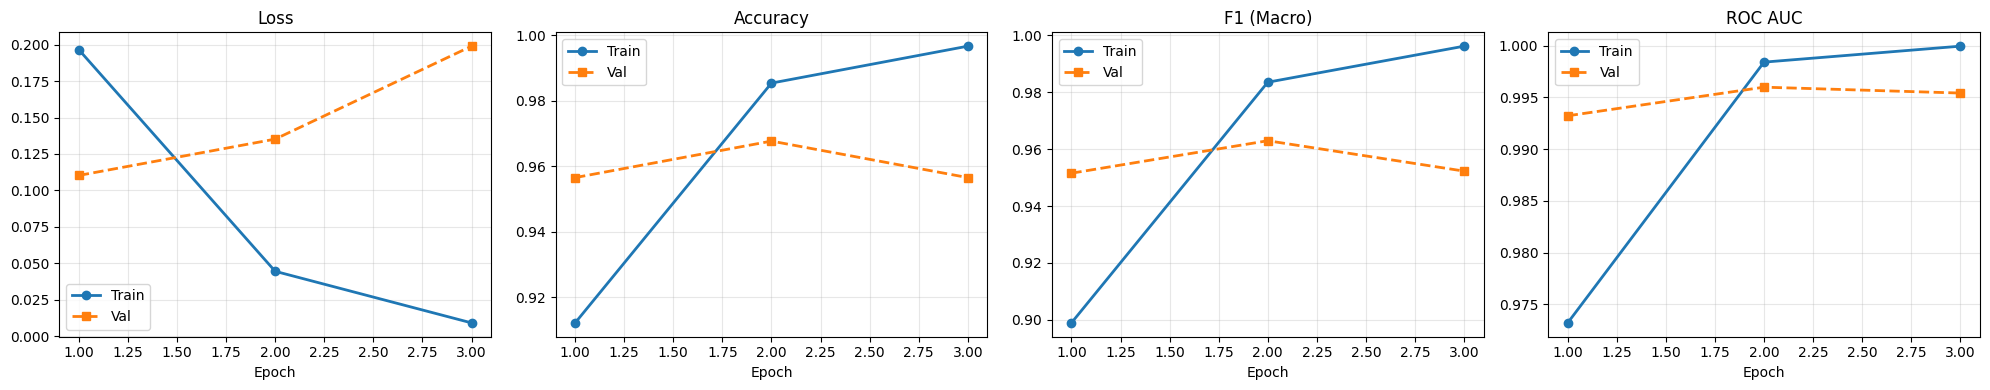

In [14]:
def plot_training_curves(history):
    """Plot train vs val metrics across epochs."""
    metrics = ["loss", "accuracy", "f1_macro", "roc_auc"]
    titles  = ["Loss", "Accuracy", "F1 (Macro)", "ROC AUC"]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    for ax, metric, title in zip(axes, metrics, titles):
        train_v = [h[metric] for h in history["train"]]
        val_v   = [h[metric] for h in history["val"]]
        epochs  = range(1, len(train_v) + 1)

        ax.plot(epochs, train_v, "o-", label="Train", linewidth=2)
        ax.plot(epochs, val_v, "s--", label="Val", linewidth=2)
        ax.set_xlabel("Epoch")
        ax.set_title(title)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_training_curves(history)

## 10. Full Evaluation on All Splits

Load the best checkpoint (selected by val ROC AUC) and evaluate all three splits:
- **Train**: How well the model fits the training data (expect high).
- **Val**: The signal used for model selection (expect slightly lower).
- **Test**: Unbiased final estimate — this is what you report in the paper.

In [15]:
def full_evaluate(model, loader, device, desc="Evaluating"):
    """
    Run inference on a full dataloader and collect results.

    Returns:
        labels:      np.array of ground-truth labels (0=real, 1=fake)
        preds:       np.array of predicted labels (0 or 1)
        probs:       np.array of P(fake) probabilities (for ROC AUC)
        model_names: np.array of generator model names (for per-family breakdown)
    """
    model.eval()
    all_preds, all_labels, all_probs, all_models = [], [], [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc=desc, leave=False):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["label"]

            logits = model(pixel_values)
            probs = torch.softmax(logits, dim=1)[:, 1]  # P(fake)
            preds = logits.argmax(dim=1)                 # hard prediction

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
            all_models.extend(batch["model_name"])

    return np.array(all_labels), np.array(all_preds), np.array(all_probs), np.array(all_models)

In [16]:
# Load best checkpoint — the state that achieved highest val ROC AUC
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
log.info("Best checkpoint loaded for evaluation")

# Evaluate all three splits with the same best model
train_labels, train_preds, train_probs, train_models = full_evaluate(model, train_loader, DEVICE, "Eval train")
val_labels,   val_preds,   val_probs,   val_models   = full_evaluate(model, val_loader,   DEVICE, "Eval val")
test_labels,  test_preds,  test_probs,  test_models  = full_evaluate(model, test_loader,  DEVICE, "Eval test")

[INFO] Best checkpoint loaded for evaluation


Eval train:   0%|          | 0/225 [00:00<?, ?it/s]

Eval val:   0%|          | 0/29 [00:00<?, ?it/s]

Eval test:   0%|          | 0/29 [00:00<?, ?it/s]

## 11. Metric Computation

Every result is reported as a structured table:

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Real | ... | ... | ... | ... |
| Fake | ... | ... | ... | ... |
| **Macro Avg** | ... | ... | ... | ... |

Plus two scalar metrics:
- **Accuracy**: Fraction of all predictions that are correct.
- **ROC AUC**: Area Under the Receiver Operating Characteristic curve. Measures how well the model's *probabilities* separate real from fake across all possible thresholds. 1.0 = perfect, 0.5 = random.

**What is Support?** The number of actual samples in that class. For example, if the test set has 300 real and 600 fake images, Support = 300 for Real and 600 for Fake. This tells you how much data backs each metric — a high F1 over 10 samples is much less reliable than over 1000.

In [17]:
def compute_metrics_table(y_true, y_pred, y_prob, label_names=("Real", "Fake")):
    """
    Compute a structured metrics dictionary.

    Args:
        y_true:       Ground-truth labels (0 or 1).
        y_pred:       Predicted labels (0 or 1).
        y_prob:       Predicted P(fake) probabilities (for ROC AUC).
        label_names:  Display names for class 0 and class 1.

    Returns:
        Dict with 'table' (DataFrame), 'accuracy', 'roc_auc', 'confusion_matrix'.
    """
    acc = accuracy_score(y_true, y_pred)

    # Per-class metrics (average=None returns array: [class_0, class_1])
    prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    rec  = recall_score(y_true, y_pred, average=None, zero_division=0)
    f1   = f1_score(y_true, y_pred, average=None, zero_division=0)

    # Macro average: simple mean across classes (treats both equally)
    prec_m = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec_m  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1_m   = f1_score(y_true, y_pred, average="macro", zero_division=0)

    # ROC AUC needs both classes present
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float("nan")

    # Confusion matrix: rows = actual, columns = predicted
    cm = confusion_matrix(y_true, y_pred)

    # Build per-class rows
    rows = []
    for i, name in enumerate(label_names):
        if i < len(prec):
            rows.append({
                "Class": name,
                "Precision": round(float(prec[i]), 4),
                "Recall": round(float(rec[i]), 4),
                "F1": round(float(f1[i]), 4),
                "Support": int((y_true == i).sum()),  # count of samples in this class
            })

    # Macro average row
    rows.append({
        "Class": "Macro Avg",
        "Precision": round(prec_m, 4),
        "Recall": round(rec_m, 4),
        "F1": round(f1_m, 4),
        "Support": len(y_true),
    })

    return {
        "table": pd.DataFrame(rows).set_index("Class"),
        "accuracy": round(acc, 4),
        "roc_auc": round(auc, 4) if not np.isnan(auc) else "N/A",
        "confusion_matrix": cm,
    }


def print_metrics(result, title):
    """Pretty-print a metrics result dict."""
    print(f"\n{'='*60}")
    print(f"  {title}")
    print(f"{'='*60}")
    print(f"  Accuracy: {result['accuracy']}")
    print(f"  ROC AUC:  {result['roc_auc']}")
    print()
    print(result["table"].to_string())
    print(f"{'='*60}")

## 12. Overall Results: Train / Val / Test

In [18]:
# Compute structured metrics for all three splits
overall_train = compute_metrics_table(train_labels, train_preds, train_probs)
overall_val   = compute_metrics_table(val_labels,   val_preds,   val_probs)
overall_test  = compute_metrics_table(test_labels,  test_preds,  test_probs)

print_metrics(overall_train, "OVERALL — TRAIN SET")
print_metrics(overall_val,   "OVERALL — VALIDATION SET")
print_metrics(overall_test,  "OVERALL — TEST SET")


  OVERALL — TRAIN SET
  Accuracy: 0.9911
  ROC AUC:  1.0

           Precision  Recall      F1  Support
Class                                        
Real          1.0000  0.9733  0.9865     2400
Fake          0.9868  1.0000  0.9934     4791
Macro Avg     0.9934  0.9867  0.9899     7191

  OVERALL — VALIDATION SET
  Accuracy: 0.9677
  ROC AUC:  0.996

           Precision  Recall      F1  Support
Class                                        
Real          0.9892  0.9133  0.9497      300
Fake          0.9581  0.9950  0.9762      598
Macro Avg     0.9737  0.9542  0.9630      898

  OVERALL — TEST SET
  Accuracy: 0.9511
  ROC AUC:  0.9921

           Precision  Recall      F1  Support
Class                                        
Real          0.9776  0.8733  0.9225      300
Fake          0.9399  0.9900  0.9643      600
Macro Avg     0.9587  0.9317  0.9434      900


## 13. Confusion Matrices: Train / Val / Test

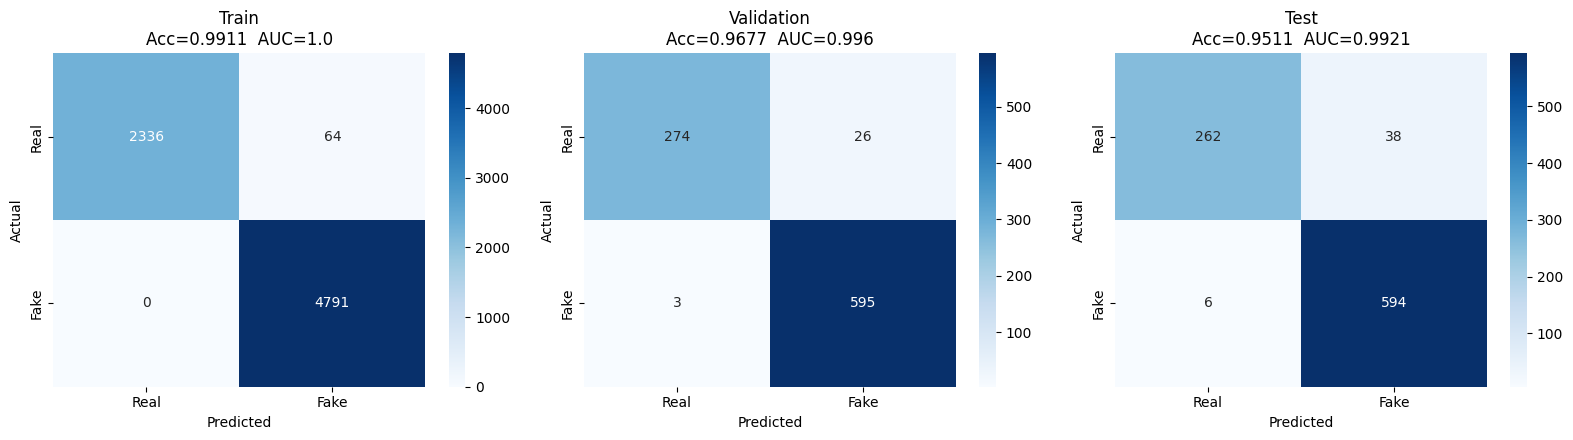

In [19]:
def plot_confusion_matrix(cm, class_names, title, ax):
    """Plot a single confusion matrix heatmap on the given axes."""
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

# Plot all three splits side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
class_names = ["Real", "Fake"]

for ax, (result, split_name) in zip(axes, [
    (overall_train, "Train"),
    (overall_val,   "Validation"),
    (overall_test,  "Test"),
]):
    plot_confusion_matrix(
        result["confusion_matrix"], class_names,
        f"{split_name}\nAcc={result['accuracy']}  AUC={result['roc_auc']}", ax
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices_splits.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Per-Family Results (Test Set)

Three families: **Real**, **Stable Diffusion**, **Midjourney**.

For each family, we filter the test set to only samples from that family and compute the same metrics table. This shows whether the model generalises equally across generator architectures.

**Note**: For the Real family, all labels are 0 (real), so Fake-class metrics will show zeros — this is expected. The useful number is the Real row's Recall (what fraction of real images are correctly classified as real).

In [20]:
# Map each test sample's generator model to its family
test_families = np.array([MODEL_TO_FAMILY.get(m, "Unknown") for m in test_models])
unique_families = sorted(set(test_families))

family_results = {}

for fam in unique_families:
    # Boolean mask: which test samples belong to this family
    mask = test_families == fam
    if mask.sum() == 0:
        continue

    result = compute_metrics_table(test_labels[mask], test_preds[mask], test_probs[mask])
    family_results[fam] = result
    print_metrics(result, f"FAMILY: {fam}  (n={mask.sum()})")


  FAMILY: Midjourney  (n=304)
  Accuracy: 0.9967
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             0.0  0.0000  0.0000        0
Fake             1.0  0.9967  0.9984      304
Macro Avg        0.5  0.4984  0.4992      304

  FAMILY: Real  (n=300)
  Accuracy: 0.8733
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             1.0  0.8733  0.9324      300
Fake             0.0  0.0000  0.0000        0
Macro Avg        0.5  0.4367  0.4662      300

  FAMILY: Stable Diffusion  (n=296)
  Accuracy: 0.9831
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             0.0  0.0000  0.0000        0
Fake             1.0  0.9831  0.9915      296
Macro Avg        0.5  0.4916  0.4957      296


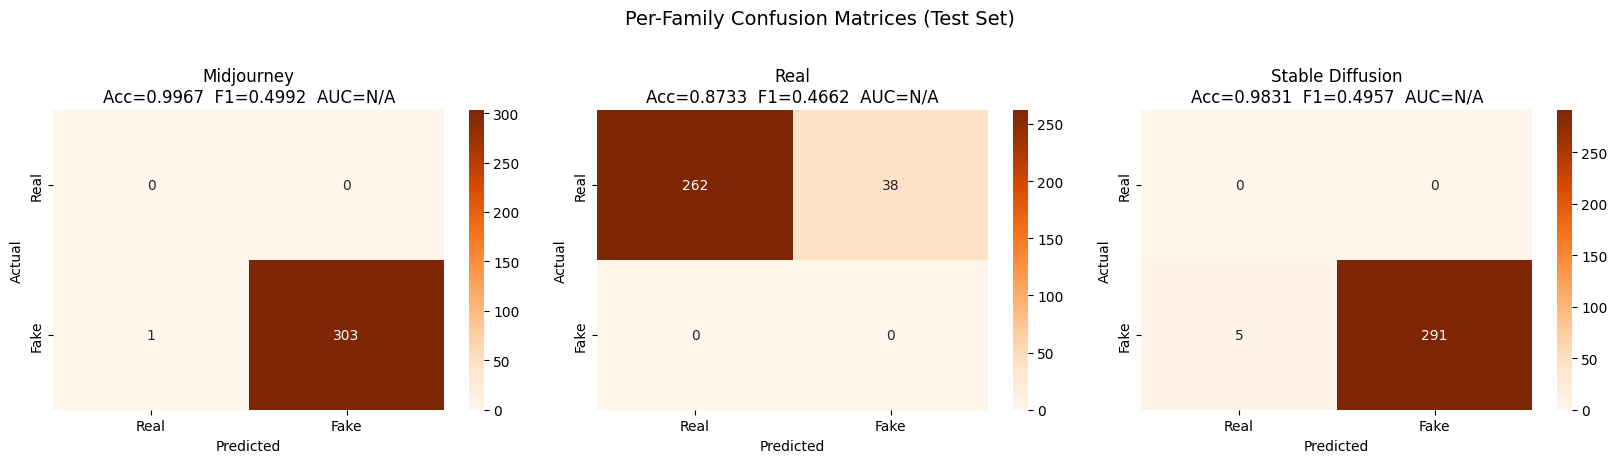

In [21]:
# ── Per-family confusion matrices side by side ──
n_fam = len(family_results)
fig, axes = plt.subplots(1, n_fam, figsize=(5.5 * n_fam, 4.5))
if n_fam == 1:
    axes = [axes]

for ax, (fam, res) in zip(axes, sorted(family_results.items())):
    cm = res["confusion_matrix"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"], ax=ax)
    macro_f1 = res["table"].loc["Macro Avg", "F1"]
    ax.set_title(f"{fam}\nAcc={res['accuracy']}  F1={macro_f1}  AUC={res['roc_auc']}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Per-Family Confusion Matrices (Test Set)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices_per_family.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Summary Bar Chart

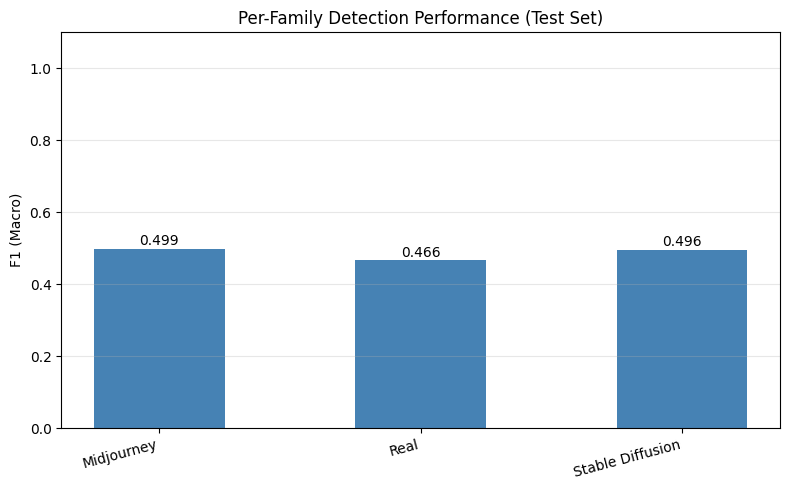

In [22]:
if len(family_results) > 1:
    fam_names = sorted(family_results.keys())
    fam_f1s = [family_results[f]["table"].loc["Macro Avg", "F1"] for f in fam_names]

    x = np.arange(len(fam_names))

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(x, fam_f1s, color="steelblue", width=0.5)

    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=10)

    ax.set_xticks(x)
    ax.set_xticklabels(fam_names, rotation=15, ha="right")
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("F1 (Macro)")
    ax.set_title("Per-Family Detection Performance (Test Set)")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "per_family_bar_chart.png", dpi=150, bbox_inches="tight")
    plt.show()

## 16. Save Everything

In [23]:
# ── 1. Final model state (last epoch, for reference) ──

# ── 2. LoRA adapter (small, portable) ──
# Can be loaded on top of any CLIP ViT-L/14 without the full checkpoint.
lora_dir = OUTPUT_DIR / "lora_adapter"
lora_dir.mkdir(exist_ok=True)
model.vision_model.save_pretrained(str(lora_dir))
log.info(f"LoRA adapter → {lora_dir}")

# ── 3. All metrics as JSON ──
def table_to_dict(df):
    """Convert a metrics DataFrame to a list of dicts for JSON."""
    return df.reset_index().to_dict(orient="records")

results_to_save = {
    "config": {k: str(v) if isinstance(v, Path) else v for k, v in CONFIG.items()},
    # Overall metrics for each split
    "overall_train": {
        "metrics": table_to_dict(overall_train["table"]),
        "accuracy": overall_train["accuracy"],
        "roc_auc": overall_train["roc_auc"],
        "confusion_matrix": overall_train["confusion_matrix"].tolist(),
    },
    "overall_val": {
        "metrics": table_to_dict(overall_val["table"]),
        "accuracy": overall_val["accuracy"],
        "roc_auc": overall_val["roc_auc"],
        "confusion_matrix": overall_val["confusion_matrix"].tolist(),
    },
    "overall_test": {
        "metrics": table_to_dict(overall_test["table"]),
        "accuracy": overall_test["accuracy"],
        "roc_auc": overall_test["roc_auc"],
        "confusion_matrix": overall_test["confusion_matrix"].tolist(),
    },
    # Per-family metrics (test set)
    "per_family_test": {
        fam: {
            "metrics": table_to_dict(res["table"]),
            "accuracy": res["accuracy"],
            "roc_auc": res["roc_auc"],
            "confusion_matrix": res["confusion_matrix"].tolist(),
        }
        for fam, res in family_results.items()
    },
    # Training history (for reproducing curves)
    "training_history": history,
    "early_stopped_at_epoch": len(history["train"]),
    "best_val_roc_auc": early_stopper.best_score,
    "timestamp": datetime.now().isoformat(),
}

with open(OUTPUT_DIR / "results.json", "w") as f:
    json.dump(results_to_save, f, indent=2, default=str)

log.info(f"Results JSON → {OUTPUT_DIR / 'results.json'}")

print("\n✅ All outputs saved to:", OUTPUT_DIR)
print("   • best_model.pt                    (best val ROC AUC checkpoint)")
print("   • final_model.pt                   (last epoch state)")
print("   • lora_adapter/                    (portable LoRA weights)")
print("   • results.json                     (all metrics + config + history)")
print("   • training_curves.png")
print("   • confusion_matrices_splits.png    (train / val / test side by side)")
print("   • confusion_matrices_per_family.png")
print("   • per_family_bar_chart.png")

[INFO] LoRA adapter → /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs/lora_adapter
[INFO] Results JSON → /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs/results.json

✅ All outputs saved to: /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs
   • best_model.pt                    (best val ROC AUC checkpoint)
   • final_model.pt                   (last epoch state)
   • lora_adapter/                    (portable LoRA weights)
   • results.json                     (all metrics + config + history)
   • training_curves.png
   • confusion_matrices_splits.png    (train / val / test side by side)
   • confusion_matrices_per_family.png
   • per_family_bar_chart.png


---

## Notes for Paper Reporting

**Which numbers to report:**
- **Test set** metrics are your primary results — unbiased since the model never saw this data.
- **Train and val** metrics in supplementary material show the model isn't overfitting (train >> test would be a red flag).

**Metric definitions (for your methodology section):**
- **Precision**: Of all images predicted as [class], what fraction actually were? High precision = few false positives.
- **Recall**: Of all actual [class] images, what fraction did the model catch? High recall = few false negatives.
- **F1**: Harmonic mean of precision and recall — balances both.
- **Support**: Number of actual samples in that class — shows how much data backs each metric.
- **Accuracy**: Overall fraction correct across all samples.
- **ROC AUC**: Area under the Receiver Operating Characteristic curve — measures how well the model's probability scores separate real from fake across all possible thresholds. 1.0 = perfect, 0.5 = random.

Set `DEBUG = True` to validate the full pipeline on ~100 samples before committing to a full run.

## 17. Zero-shot evaluation function

In [24]:
def zero_shot_evaluate(model_name, loader, device, desc="Zero-shot"):
    """
    Zero-shot deepfake detection using CLIP's text-image similarity.

    Instead of a trained classifier, we compare each image's CLIP embedding
    against two text prompts:
      - "a real photograph" (class 0)
      - "an AI generated image" (class 1)
    The class with higher cosine similarity wins.
    """
    from transformers import CLIPModel, CLIPProcessor

    clip = CLIPModel.from_pretrained(model_name).to(device)
    proc = CLIPProcessor.from_pretrained(model_name)
    clip.eval()

    # Encode the two class prompts once
    text_inputs = proc(
        text=["a real photograph", "an AI generated image"],
        return_tensors="pt", padding=True
    ).to(device)

    with torch.no_grad():
        text_embeds = clip.get_text_features(**text_inputs)
        if not isinstance(text_embeds, torch.Tensor):
            text_embeds = text_embeds.pooler_output
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)  # L2 normalise

    all_labels, all_preds, all_probs, all_models = [], [], [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc=desc, leave=False):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["label"]

            # Get image embeddings from CLIP
            image_embeds = clip.get_image_features(pixel_values=pixel_values)
            if not isinstance(image_embeds, torch.Tensor):
                image_embeds = image_embeds.pooler_output
            image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)

            # Cosine similarity with both text prompts → [B, 2]
            similarity = image_embeds @ text_embeds.T

            # P(fake) = softmax over the two similarities, take the "AI generated" column
            probs_both = torch.softmax(similarity * 100.0, dim=1)  # scale by CLIP's logit_scale (~100)
            prob_fake = probs_both[:, 1]
            preds = similarity.argmax(dim=1)  # 0 = real, 1 = fake

            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(prob_fake.cpu().numpy())
            all_models.extend(batch["model_name"])

    # Free memory — we don't need the full CLIP model after this
    del clip
    torch.cuda.empty_cache()

    return np.array(all_labels), np.array(all_preds), np.array(all_probs), np.array(all_models)

## 18. Run zero-shot on all splits

In [25]:
print("=" * 60)
print("  ZERO-SHOT BASELINE (no training, CLIP text-image similarity)")
print("=" * 60)

zs_test_labels, zs_test_preds, zs_test_probs, zs_test_models = zero_shot_evaluate(
    CONFIG["model_name"], test_loader, DEVICE, "ZS test"
)

zs_overall_test = compute_metrics_table(zs_test_labels, zs_test_preds, zs_test_probs)
print_metrics(zs_overall_test, "ZERO-SHOT — TEST SET")

  ZERO-SHOT BASELINE (no training, CLIP text-image similarity)


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ZS test:   0%|          | 0/29 [00:00<?, ?it/s]


  ZERO-SHOT — TEST SET
  Accuracy: 0.6067
  ROC AUC:  0.5086

           Precision  Recall      F1  Support
Class                                        
Real          0.3608  0.2333  0.2834      300
Fake          0.6742  0.7933  0.7289      600
Macro Avg     0.5175  0.5133  0.5062      900
